# Models without spatial information

Linear, LSTM, TCN and encoder-decoder LSTM, trained with BasicTS on METR-LA (shared settings: `make_cfg` in `src/utils/config.py`):
- 12 steps in → 12 out;
- one model shared by all sensors;
- missing values (0) handled as in DCRNN;
- scaler from the training data (mean 54.41, std 19.49);
- early stopping on validation MAE;
- test set evaluated once at the end of each run.

Contents: first results (speed only, default settings), input features (task 4), tuning (task 5), final runs with 3 seeds (task 9), comparison with Step 1 and the DCRNN paper (task 6), all sensors as input (task 10, MLP), error analysis (tasks 7–8, on the first runs).

#### Check: the models use no spatial information

In [61]:
import torch
from src.model.baseline_temporal_models.linear import Linear, LinearConfig
from src.model.baseline_temporal_models.lstm import LSTM, LSTMConfig
from src.model.baseline_temporal_models.tcn import TCN, TCNConfig

torch.manual_seed(0)
x = torch.randn(2, 12, 207)            # 2 windows, 12 steps, 207 sensors
x2 = x.clone()
x2[:, :, 5] += 10                      # change sensor 5's input

for name, m in [('Linear', Linear(LinearConfig())), ('LSTM', LSTM(LSTMConfig())), ('TCN', TCN(TCNConfig()))]:
    with torch.no_grad():
        diff = (m(x2) - m(x)).abs().amax(dim=(0, 1))      # biggest change in each sensor's output
    print(f'{name}: output changed for sensors {torch.nonzero(diff > 1e-6).flatten().tolist()}')

Linear: output changed for sensors [5]
LSTM: output changed for sensors [5]
TCN: output changed for sensors [5]


Changing one sensor's input only changes that sensor's forecast: the models use no information from other sensors.

### First results (tasks 3 and 6) 
#### Test results of the first runs (speed only, no tuning yet)

In [62]:
import json
from pathlib import Path
import pandas as pd

rows = []
for path in Path('checkpoints').glob('*/METR-LA_*_12_12/*/test_metrics.json'):
    model, run = path.parts[-4], path.parts[-3]
    m = json.loads(path.read_text())
    for h, minutes in [(3, 15), (6, 30), (12, 60)]:
        r = m[f'horizon_{h}']
        rows.append({'model': model, 'run': run, 'minutes': minutes,
                     'MAE': r['MAE'], 'RMSE': r['RMSE'], 'MAPE %': 100 * r['MAPE']})

table = pd.DataFrame(rows).pivot_table(index=['model', 'run'], columns='minutes',
                                       values=['MAE', 'RMSE', 'MAPE %']).round(2)
table

MAE             MAPE %                RMSE         \
minutes                     15    30    60     15     30     60    15     30   
model  run                                                                     
LSTM   METR-LA_100_12_12  3.22  3.90  5.03   8.78  11.10  15.04  6.29   7.81   
       METR-LA_10_12_12   3.27  3.96  5.08   9.14  11.46  15.34  6.40   7.89   
Linear METR-LA_100_12_12  3.81  4.81  6.28   9.37  12.32  17.14  8.17  10.25   
       METR-LA_2_12_12    4.13  5.02  6.67  10.20  12.89  18.17  8.53  10.35   
TCN    METR-LA_100_12_12  3.14  3.84  4.98   8.57  10.93  14.97  6.17   7.75   
       METR-LA_10_12_12   3.15  3.85  4.99   8.58  10.96  14.81  6.16   7.73   

                                 
minutes                      60  
model  run                       
LSTM   METR-LA_100_12_12   9.83  
       METR-LA_10_12_12    9.88  
Linear METR-LA_100_12_12  12.37  
       METR-LA_2_12_12    12.62  
TCN    METR-LA_100_12_12   9.78  
       METR-LA_10_12_12    9.79

All three models beat the last-value rule at every horizon. 
- TCN is best (test MAE 3.14 / 3.84 / 4.98 at 15 / 30 / 60 min), slightly ahead of LSTM (3.22 / 3.90 / 5.03), with 2.6× fewer parameters (6,796 vs 17,932) 
- LSTM and TCN beat both Step 1 rules at 15 and 30 minutes, but at 60 minutes the weekly average is still best (4.19).
- The linear model has a much higher RMSE (8.17 at 15 min), so it makes some very large errors. One possible cause is missing inputs (0 mph → −2.79 after scaling), which a linear model cannot ignore.

#### Test MAE by horizon vs the Step 1 rules

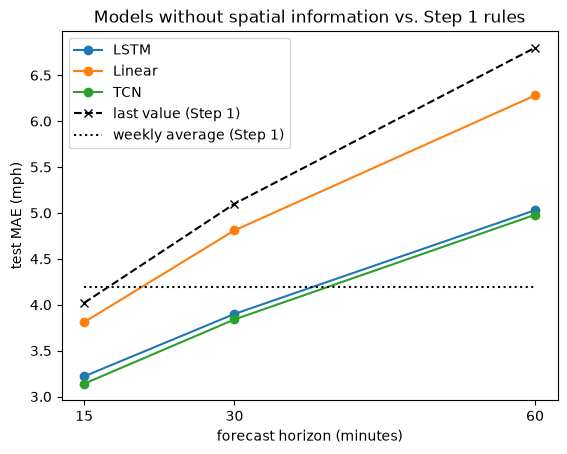

In [63]:
import matplotlib.pyplot as plt

mae = table['MAE']
for (model, run), row in mae.iterrows():
    if run == 'METR-LA_2_12_12' or run == 'METR-LA_10_12_12':
        continue
    plt.plot(row.index, row.values, marker='o', label=model)
    
plt.plot([15, 30, 60], [4.02, 5.10, 6.80], 'k--', marker='x', label='last value (Step 1)')
plt.plot([15, 30, 60], [4.19, 4.19, 4.19], 'k:', label='weekly average (Step 1)')
plt.xticks([15, 30, 60])
plt.xlabel('forecast horizon (minutes)')
plt.ylabel('test MAE (mph)')
plt.title('Models without spatial information vs. Step 1 rules')
plt.legend()
plt.savefig('notebooks/plots/step2_mae_by_horizon.png', dpi=150, bbox_inches='tight')
plt.show()

All three models are trained fully, with early stopping (training stops after 10 epochs without improvement on the validation set): 
- Linear stopped at epoch 31 (best 21);
- LSTM at epoch 79 (best 69);
- TCN at epoch 28 (best 18). 

Compared with the first runs limited to 10 epochs, training to the end changed little: LSTM 5.08 → 5.03 and TCN 4.99 → 4.98 at 60 minutes. 

Training time on the CPU: Linear 3 min, LSTM 2.6 h, TCN 56 min.

### Input features (task 4)
#### Which inputs help (TCN, 10 epochs)

In [64]:
import json
from pathlib import Path
import pandas as pd
import torch

runs = {'speed (12 steps)': Path('checkpoints/TCN/METR-LA_10_12_12')}
runs.update({p.name.removeprefix('TCN_'): p for p in Path('checkpoints/features').glob('TCN_*')})

rows = []
for name, folder in runs.items():
    ckpt = next(folder.glob('*/TCN_best_val_MAE.pt'), None)
    if ckpt is None or not (ckpt.parent / 'test_metrics.json').exists():
        continue                                  # run not finished yet
    best = torch.load(ckpt, map_location='cpu')
    test = json.loads((ckpt.parent / 'test_metrics.json').read_text())
    rows.append({'inputs': name, 
                 'best epoch': best['epoch'], 
                 'val MAE': best['best_metrics']['val/MAE'],
                 'test MAE 15': test['horizon_3']['MAE'], 
                 'test MAE 30': test['horizon_6']['MAE'],
                 'test MAE 60': test['horizon_12']['MAE']})
pd.DataFrame(rows).round(3)


,inputs,best epoch,val MAE,test MAE 15,test MAE 30,test MAE 60
0,speed (12 steps),9,3.474,3.150,3.854,4.995
1,speed+tod,7,3.410,3.126,3.766,4.752
2,speed+tod+dow,10,3.344,3.115,3.740,4.651
3,speed+tod+dow_in36,10,3.267,3.074,3.665,4.509
4,speed_in24,9,3.449,3.142,3.835,4.954
5,speed_in36,10,3.412,3.117,3.803,4.922


Inputs were tested on the TCN with the first-run settings (10 epochs each). An input was kept only if the validation MAE dropped.
- Time of day (sine/cosine) lowers the validation MAE from 3.474 to 3.410, and adding day of week lowers it further to 3.344. The gain is largest at 60 minutes (4.99 → 4.65), where the gap to the weekly average shrinks from 0.80 to 0.46 mph.
- A longer input (speed only) also helps: 24 steps gives 3.449 and 36 steps (3 hours) gives 3.412, about as much as time of day on validation. At 60 minutes, however, the gain is small (4.92, compared with 4.75 for time of day), and training is 3× slower, because the TCN needs 6 layers instead of 4 to see 36 steps.
- Chosen: 12 steps of speed + time of day + day of week, used for all tuning and final runs (tasks 5 and 9). I could also test: 36 steps together with time of day and day of week.

### Hyperparameter tuning (task 5)

Optuna, with the same rules for every model:
- the same budget: **20 tries per model**, each trained for at most **10 epochs**, judged on the **validation MAE**;
- the same inputs: 12 steps of speed + time of day + day of week (best inputs from task 4), batch size 64;
- the first try (try 0) is the current settings, so the gain from tuning is measured directly;
- a try that is clearly worse is **stopped early** to save time: from epoch 3 on, if its validation MAE is worse than the median of the finished tries at the same epoch (the first 3 tries are never stopped).

| Model | Settings searched | Current (try 0) |
|---|---|---|
| Linear | learning rate | 0.001 |
| TCN | channels 16 / 32 / 64, kernel 2 / 3, layers 4 / 5, learning rate | 32, 2, 4, 0.001 |
| LSTM | hidden units 32 / 64 / 128, layers 1 / 2, dropout 0–0.3 (2 layers only), learning rate | 64, 1, –, 0.001 |
| Encoder-decoder LSTM | the LSTM settings + teacher forcing yes / no | 64, 1, –, 0.001, no |

Learning rate: 0.0003–0.01 on a log scale, for every model.

Tuning ran in two rounds of 10 tries per model. The encoder-decoder LSTM was added in round 2 and got all 20 tries with the round-2 rules. Every try is scored the same way, by its best validation MAE within 10 epochs, so tries from both rounds can be compared. Two things changed for round 2:
- the learning-rate range was widened from 0.0003–0.003 to 0.0003–0.01, because the best round-1 tries were in the upper part of the old range;
- a try is stopped early only if it is worse than the median **and** has not improved for 3 epochs. Round 1 had stopped some Linear tries for differences under 0.001 mph, and the 128-unit LSTM while it was still improving. Round 2 ran these LSTM settings to the end (128 units: 3.446; 128×2: 3.45–3.46), and none beat the best.

Code: `src/utils/tuning/nn_tuning.py`. All tries are stored in `checkpoints/tuning/optuna.db`.

### All tuning tries

In [65]:
import matplotlib.pyplot as plt
import optuna
import pandas as pd
from matplotlib.lines import Line2D

optuna.logging.set_verbosity(optuna.logging.WARNING)
TUNED = ['Linear', 'TCN', 'LSTM', 'EncoderDecoderLSTM']

rows = []
for name in TUNED:
    study = optuna.load_study(study_name=name, storage='sqlite:///checkpoints/tuning/optuna.db')
    best = study.best_trial.number                  # lowest validation MAE among the tries that finished
    for t in study.trials:
        if t.state.name not in ('COMPLETE', 'PRUNED'):
            continue
        curve = [t.intermediate_values[e] for e in sorted(t.intermediate_values)]   # validation MAE after each epoch
        stopped = t.state.name == 'PRUNED'
        role = 'current' if t.number == 0 else 'best' if t.number == best else 'stopped' if stopped else 'other'
        rows.append({'model': name, 'try': t.number, 'role': role, 'stopped': stopped, 'curve': curve,
                     'epochs': len(curve), 'val_mae': min(curve), **t.params,
                     'n_params': t.user_attrs['n_params'], 'minutes': t.user_attrs['minutes']})
tries = pd.DataFrame(rows)
tries.groupby('model', sort=False).agg(tries=('try', 'size'), stopped_early=('stopped', 'sum'))

,tries,stopped_early
model,,
Linear,20,8
TCN,20,4
LSTM,20,5
EncoderDecoderLSTM,20,2


### Validation MAE per epoch, every try

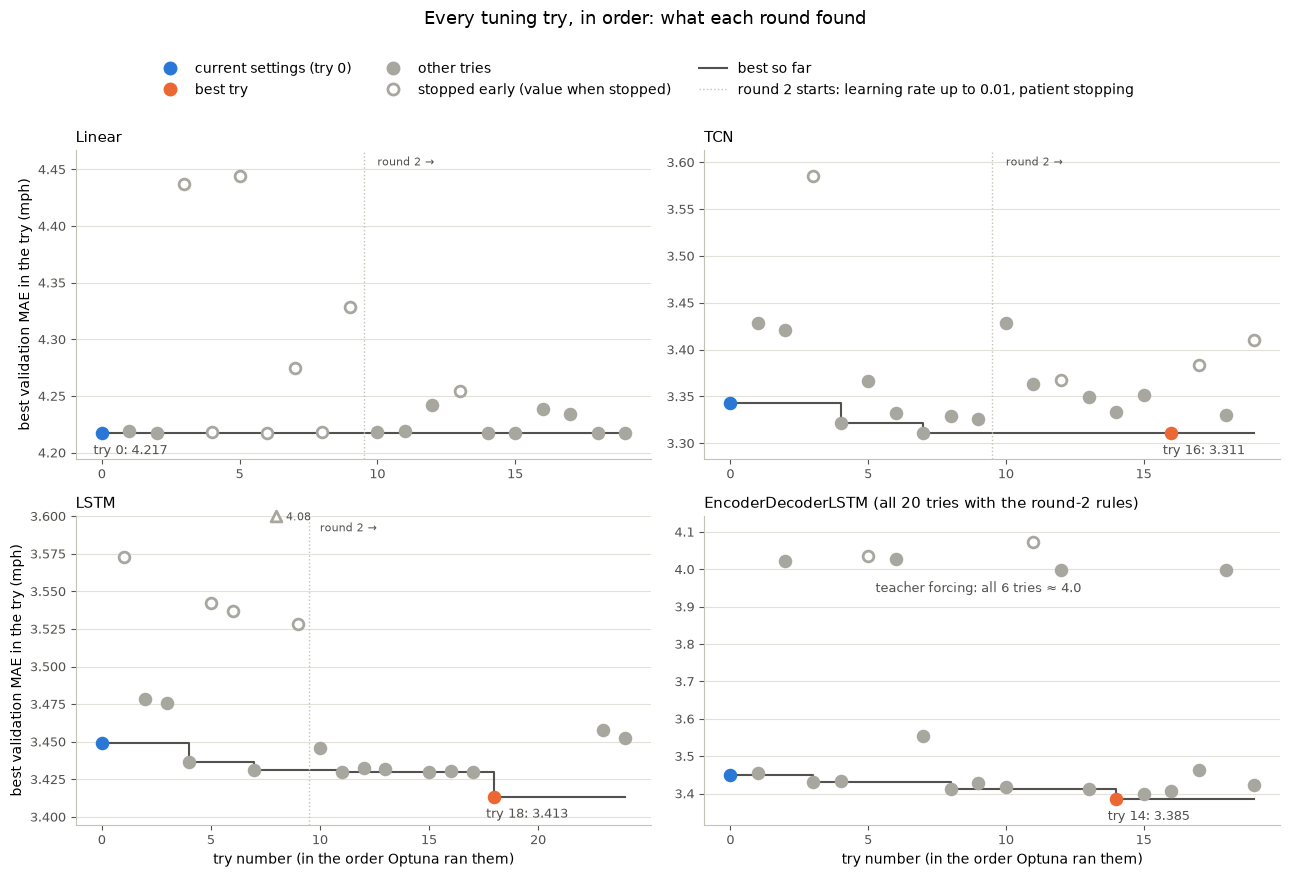

In [66]:
COLORS = {'current': '#2a78d6', 'best': '#eb6834', 'other': '#a8a79f', 'stopped': '#a8a79f'}
INK2, GRID, AXIS = '#52514e', '#e1e0d9', '#c3c2b7'


def style(ax):
    ax.grid(axis='y', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=INK2, labelsize=9)


YMAX = {'LSTM': 3.60}
ROUND2 = 10

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, name in zip(axes.flat, TUNED):
    sub = tries[tries.model == name].sort_values('try')
    ax.set_ymargin(0.1)                                                   # room for the labels under the points
    best_so_far = sub.val_mae.where(~sub.stopped).cummin().ffill()      # only finished tries can be "best"
    ax.step(sub['try'], best_so_far, where='post', color=INK2, lw=1.5, zorder=2)

    top = YMAX.get(name)
    for _, r in sub.iterrows():
        off_scale = top is not None and r.val_mae > top
        y = top if off_scale else r.val_mae
        c = COLORS[r.role]
        ax.scatter(r['try'], y, s=60, marker='^' if off_scale else 'o', edgecolors=c,
                   facecolors='white' if r.stopped else c, linewidths=2, zorder=3, clip_on=False)
        if off_scale:
            ax.annotate(f'{r.val_mae:.2f}', (r['try'], y), xytext=(7, -3), textcoords='offset points',
                        fontsize=8, color=INK2)
    if top is not None:
        ax.set_ylim(top=top)

    b = sub.loc[sub.val_mae.where(~sub.stopped).idxmin()]               # the best try: label it
    ax.annotate(f'try {b["try"]}: {b.val_mae:.3f}', (b['try'], b.val_mae), xytext=(-6, -15),
                textcoords='offset points', fontsize=9, color=INK2)

    if name == 'EncoderDecoderLSTM':                                     # tuned in round 2 only
        tf = sub[sub.teacher_forcing == True]
        ax.annotate(f'teacher forcing: all {len(tf)} tries ≈ 4.0', (tf['try'].mean(), tf.val_mae.min()),
                    xytext=(0, -16), textcoords='offset points', ha='center', fontsize=9, color=INK2)
        ax.set_title(f'{name} (all 20 tries with the round-2 rules)', fontsize=11, loc='left')
    else:
        ax.axvline(ROUND2 - 0.5, color=AXIS, lw=1, ls=':')
        ax.text(ROUND2, 0.98, 'round 2 →', transform=ax.get_xaxis_transform(), va='top', fontsize=8, color=INK2)
        ax.set_title(name, fontsize=11, loc='left')
    ax.set_xticks(range(0, sub['try'].max() + 1, 5))
    style(ax)
for ax in axes[1]:
    ax.set_xlabel('try number (in the order Optuna ran them)')
for ax in axes[:, 0]:
    ax.set_ylabel('best validation MAE in the try (mph)')

dot = lambda color, face, label: Line2D([], [], ls='', marker='o', ms=8, mew=2, mec=color, mfc=face, label=label)
handles = [dot(COLORS['current'], COLORS['current'], 'current settings (try 0)'),
           dot(COLORS['best'], COLORS['best'], 'best try'),
           dot(COLORS['other'], COLORS['other'], 'other tries'),
           dot(COLORS['stopped'], 'white', 'stopped early (value when stopped)'),
           Line2D([], [], color=INK2, lw=1.5, label='best so far'),
           Line2D([], [], color=AXIS, lw=1, ls=':', label='round 2 starts: learning rate up to 0.01, patient stopping')]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.965), fontsize=10)
fig.suptitle('Every tuning try, in order: what each round found', y=1.09, fontsize=13)
fig.tight_layout()
plt.savefig('notebooks/plots/step2_tuning_tries.png', dpi=150, bbox_inches='tight')
plt.show()

- Linear: flat. Every finished try ends at 4.217–4.242. Only the ends of the learning-rate range (0.0003, and around 0.005 or higher) are slightly worse. There is nothing to tune.
- TCN: the gain comes from round 1 (3.343 → 3.311, try 7). Round 2 found nothing better: try 16 (64 channels, 34,892 parameters) beats try 7 (32 channels, 9,260 parameters) by 0.0002 mph, which is noise. The final runs use try 16 because it has the lowest value, but the 3.8× smaller try 7 is just as good on validation.
- LSTM: the only model where round 2 helps: 3.431 → 3.413 (try 18), with a learning rate of 0.0096, above the round-1 maximum.
- Encoder-decoder LSTM: 3.450 → 3.385 (try 14). The 6 teacher-forcing tries form a separate group at 4.00–4.07, compared with 3.385–3.553 for the others. With teacher forcing, the decoder sees the true previous values during training but its own forecasts during validation, so it never learns to correct its own errors. DCRNN avoids this with scheduled sampling (gradually replacing the true values with the model's own forecasts during training), which we did not try.

### Learning rate and size of every try

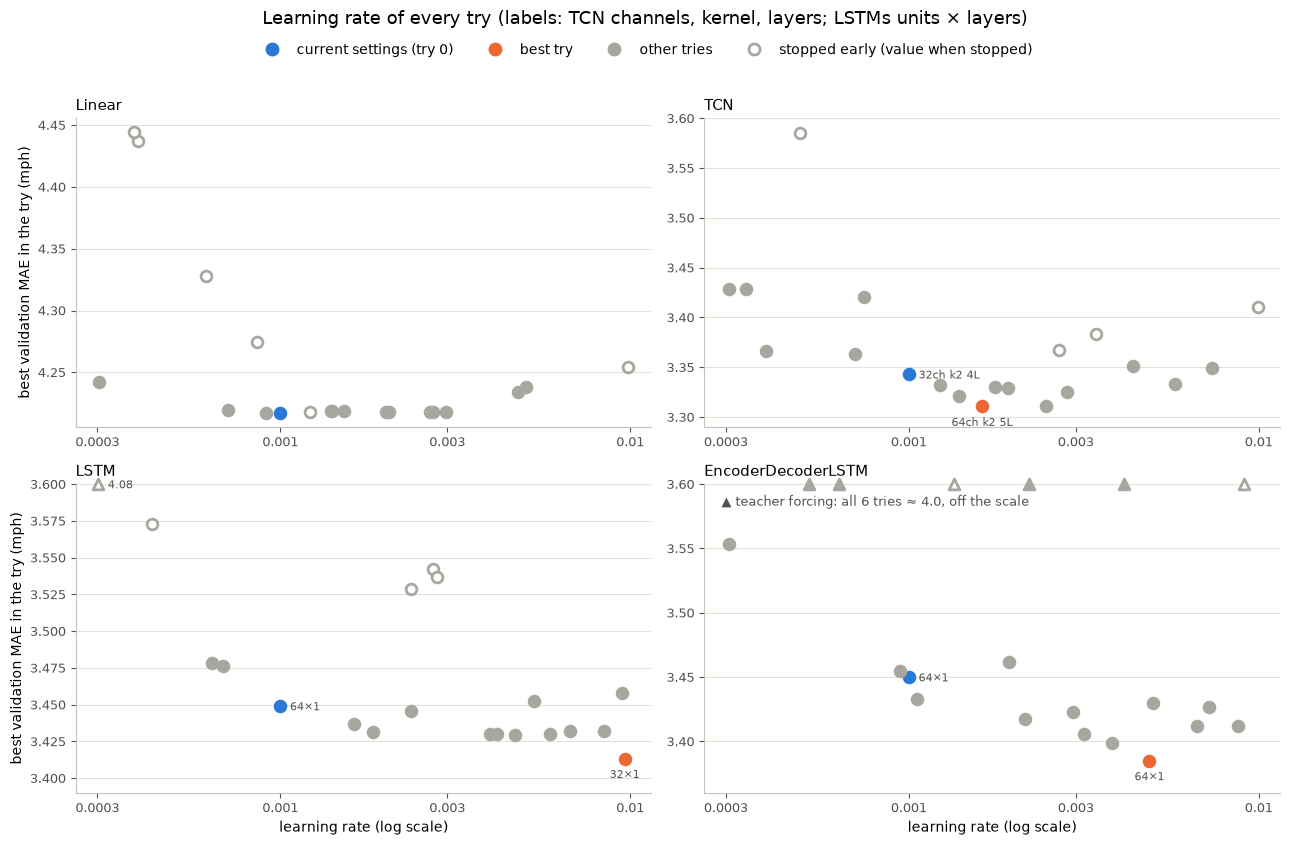

In [67]:
YLIM = {'TCN': (3.29, 3.60), 'LSTM': (3.39, 3.60), 'EncoderDecoderLSTM': (3.36, 3.60)}   # zoom in; ▲ = off the scale


def size_label(name, r):
    if name == 'TCN':
        return f'{r.channels:.0f}ch k{r.kernel_size:.0f} {r.num_layers:.0f}L'
    if name in ('LSTM', 'EncoderDecoderLSTM'):
        return f'{r.hidden_size:.0f}×{r.num_layers:.0f}'
    return ''


fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, name in zip(axes.flat, TUNED):
    sub = tries[tries.model == name]
    lo, hi = YLIM.get(name, (None, None))
    for _, r in sub.iterrows():
        c = COLORS[r.role]
        off_scale = hi is not None and r.val_mae > hi
        y = hi if off_scale else r.val_mae
        ax.scatter(r.lr, y, s=60, marker='^' if off_scale else 'o', edgecolors=c,
                   facecolors='white' if r.stopped else c, linewidths=2, zorder=3, clip_on=False)
        if r.role in ('current', 'best') and size_label(name, r):      # label the size of these two only
            dx, dy, ha = (7, -3, 'left') if r.role == 'current' else (0, -14, 'center')
            ax.annotate(size_label(name, r), (r.lr, y), xytext=(dx, dy), textcoords='offset points',
                        ha=ha, fontsize=8, color=INK2)
        if off_scale and name == 'LSTM':
            ax.annotate(f'{r.val_mae:.2f}', (r.lr, y), xytext=(7, -3), textcoords='offset points',
                        fontsize=8, color=INK2)
    if name == 'EncoderDecoderLSTM':
        ax.text(0.03, 0.93, '▲ teacher forcing: all 6 tries ≈ 4.0, off the scale', transform=ax.transAxes,
                fontsize=9, color=INK2)
    if hi is not None:
        ax.set_ylim(lo, hi)
    ax.set_xscale('log')
    ax.set_xlim(2.6e-4, 1.15e-2)
    ticks = [3e-4, 1e-3, 3e-3, 1e-2]
    ax.set_xticks(ticks, [f'{t:g}' for t in ticks])
    ax.minorticks_off()
    ax.set_title(name, fontsize=11, loc='left')
    style(ax)
for ax in axes[1]:
    ax.set_xlabel('learning rate (log scale)')
for ax in axes[:, 0]:
    ax.set_ylabel('best validation MAE in the try (mph)')
dot = lambda color, face, label: Line2D([], [], ls='', marker='o', ms=8, mew=2, mec=color, mfc=face, label=label)
handles = [dot(COLORS['current'], COLORS['current'], 'current settings (try 0)'),
           dot(COLORS['best'], COLORS['best'], 'best try'),
           dot(COLORS['other'], COLORS['other'], 'other tries'),
           dot(COLORS['stopped'], 'white', 'stopped early (value when stopped)')]
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, 0.975), fontsize=10)
fig.suptitle('Learning rate of every try (labels: TCN channels, kernel, layers; LSTMs units × layers)',
             y=1.05, fontsize=13)
fig.tight_layout()
plt.savefig('notebooks/plots/step2_tuning_lr.png', dpi=150, bbox_inches='tight')
plt.show()

Each point is one try: its best validation MAE against its learning rate (hollow: stopped early, value when it was stopped; ▲: off the scale).
- **Linear:** between 0.0007 and 0.003, every try that was not stopped at epoch 3 ends at 4.217–4.219; only the extremes are slightly worse. The learning rate changes how fast the model learns, not where it ends.
- **TCN:** there is a best range, 0.0012–0.003 (3.311–3.332, except one stopped try). Below 0.001 the tries end at 3.36–3.43 and their best epoch is the last one, so they were still learning at epoch 10; above 0.004 they get worse again (3.33–3.41). Size matters less: the best 64-channel and 32-channel tries tie (3.311); 16 channels is worse.
- **LSTM and encoder-decoder LSTM:** higher is better, up to the top of the range (best at 0.0096 and 0.0049). The best tries are not bigger than the current settings: 32 units × 1 layer for the LSTM, 64 × 1 for the encoder-decoder.
- Caveat: 10-epoch tries favour learning rates that learn fast; with longer training a lower learning rate could catch up. Learning rate and size change together in every try, so 20 tries cannot fully separate their effects.

### Current vs best settings

In [68]:
pd.set_option('display.max_colwidth', None)                       
KEYS = {'Linear': ['lr'], 'TCN': ['channels', 'kernel_size', 'num_layers', 'lr'],
        'LSTM': ['hidden_size', 'num_layers', 'lr'],
        'EncoderDecoderLSTM': ['hidden_size', 'num_layers', 'teacher_forcing', 'lr']}
fmt = lambda v: f'{v:.4g}' if isinstance(v, float) else str(v)
summary = []
for name in TUNED:
    sub = tries[tries.model == name].set_index('try')
    cur, best = sub.loc[0], sub.loc[sub[~sub.stopped].val_mae.idxmin()]
    summary.append({'model': name,
                    'val MAE, current': round(cur.val_mae, 3), 'val MAE, best': round(best.val_mae, 3),
                    'gain': round(cur.val_mae - best.val_mae, 3), 'best try': best.name,
                    'best settings': ', '.join(f'{k}={fmt(best[k])}' for k in KEYS[name]),
                    'parameters (current -> best)': f'{cur.n_params:,} -> {best.n_params:,}'})
pd.DataFrame(summary).set_index('model')

,"val MAE, current","val MAE, best",gain,best try,best settings,parameters (current -> best)
model,,,,,,
Linear,4.217,4.217,0.000,0,lr=0.001,732 -> 732
TCN,3.343,3.311,0.032,16,"channels=64, kernel_size=2, num_layers=5, lr=0.001618","7,180 -> 34,892"
LSTM,3.449,3.413,0.036,18,"hidden_size=32, num_layers=1, lr=0.009643","18,956 -> 5,388"
EncoderDecoderLSTM,3.450,3.385,0.065,14,"hidden_size=64, num_layers=1, teacher_forcing=False, lr=0.004872","36,417 -> 36,417"


**Gain from tuning** (validation MAE, 10-epoch tries): 

- TCN 3.343 → 3.311 (−0.032)
- LSTM 3.449 → 3.413 (−0.036)
- Encoder-decoder LSTM 3.450 → 3.385 (−0.065)
- Linear none
- The gains are larger than the seed-to-seed spread of the final runs (validation MAE ± 0.003–0.016, task 9), so they are probably real. The difference between the two best TCN tries (0.0002) is not.
- For comparison, adding time of day and day of week lowered the TCN validation MAE by 0.13 (3.474 → 3.344, task 4, same 10-epoch budget): the inputs matter about 4× more than the TCN settings. The TCN try 0 reproduces that task-4 run (3.343 vs 3.344).
- Bigger models did not help: the best LSTM is 3.5× smaller than the current one, the best encoder-decoder LSTM has the current size (only the learning rate changed), and the 64-channel TCN ties with a 32-channel one. The models seem limited by the information they get (one sensor's past and the time), not by their size, which is what the graph models of Step 3 change.

### Final runs with 3 seeds (task 9)

The best settings of each model, trained fully (up to 100 epochs, early stopping after 5 epochs without improvement) with seeds 42, 1 and 2 on a Kaggle GPU (T4). Each run is evaluated once on the test set. Values: mean ± standard deviation over the 3 seeds.

In [69]:
import json
import re
from pathlib import Path

import pandas as pd
import torch


def log_info():
    info = {}
    for log in Path('checkpoints/final').glob('*/*/*/training_log_*.log'):
        for sec in re.split(r'\n(?=[^\n]*Total parameters)', log.read_text()):
            if 'Total parameters' not in sec:
                continue
            ckpt = re.search(r'Checkpoint (\S+)_best_val_MAE\.pt saved', sec).group(1)   # .../<model>/<run>/<hash>/<model>
            model, run = Path(ckpt).parts[-4:-2]
            times = pd.to_datetime(re.findall(r'^(\d{4}-\d\d-\d\d \d\d:\d\d:\d\d)', sec, flags=re.M))
            info[model, run] = {'parameters': int(re.search(r'Total parameters: (\d+)', sec).group(1)),
                                'last epoch': max(int(e) for e in re.findall(r'Epoch (\d+) / ', sec)),
                                'minutes': (times[-1] - times[0]).total_seconds() / 60}
    return info


info = log_info()
rows = []
for path in Path('checkpoints/final').glob('*/*/*/test_metrics.json'):
    model, run = path.parts[-4], path.parts[-3]
    test = json.loads(path.read_text())
    best = torch.load(next(path.parent.glob('*_best_val_MAE.pt')), map_location='cpu')
    rows.append({'model': model, 'run': run, 'seed': int(run.split('seed')[1]), **info[model, run],
                 'best epoch': best['epoch'], 'val MAE': best['best_metrics']['val/MAE'],
                 **{f'MAE {m}': test[f'horizon_{h}']['MAE'] for h, m in [(3, 15), (6, 30), (12, 60)]}})
final = pd.DataFrame(rows)

ORDER = ['Linear', 'LSTM', 'EncoderDecoderLSTM', 'TCN']
tuned = final[final.run.str.startswith('tuned')].sort_values('seed')
g = tuned.groupby('model')
seeds = pd.DataFrame({'parameters': g.parameters.first().map('{:,}'.format),
                      'best / last epoch (seeds 1, 2, 42)': g[['best epoch', 'last epoch']].apply(
                          lambda d: ', '.join(f'{b}/{l}' for b, l in zip(d['best epoch'], d['last epoch']))),
                      'minutes per run': g.minutes.mean().round(0),
                      'minutes per epoch': (g.minutes.sum() / g['last epoch'].sum()).round(1)})
for col in ['val MAE', 'MAE 15', 'MAE 30', 'MAE 60']:                    # mean ± std over the 3 seeds
    seeds[col] = g[col].mean().map('{:.3f}'.format) + ' ± ' + g[col].std().map('{:.3f}'.format)
seeds.loc[ORDER]

,parameters,"best / last epoch (seeds 1, 2, 42)",minutes per run,minutes per epoch,val MAE,MAE 15,MAE 30,MAE 60
model,,,,,,,,
Linear,732,"11/16, 11/16, 8/13",4.0,0.3,4.217 ± 0.000,3.812 ± 0.003,4.810 ± 0.002,6.262 ± 0.006
LSTM,"5,388","16/21, 8/13, 6/11",8.0,0.5,3.417 ± 0.016,3.182 ± 0.010,3.809 ± 0.017,4.752 ± 0.033
EncoderDecoderLSTM,"36,417","10/15, 21/26, 9/14",40.0,2.2,3.388 ± 0.003,3.165 ± 0.014,3.773 ± 0.009,4.684 ± 0.008
TCN,"34,892","11/16, 10/15, 15/20",47.0,2.8,3.294 ± 0.012,3.072 ± 0.001,3.676 ± 0.003,4.556 ± 0.016


### Tuned models vs Step 1 and the DCRNN paper (task 6)

Test MAE at 15 / 30 / 60 minutes.

,15 min,30 min,60 min
last value (Step 1),4.02,5.10,6.80
weekly average (Step 1),4.19,4.19,4.19
Linear,3.81,4.81,6.26
LSTM,3.18,3.81,4.75
EncoderDecoderLSTM,3.17,3.77,4.68
TCN,3.07,3.68,4.56
"EncoderDecoderLSTM, FC-LSTM size (seed 42)",3.15,3.76,4.66
HA (DCRNN paper),4.16,4.16,4.16
FC-LSTM (DCRNN paper),3.44,3.77,4.37
DCRNN (DCRNN paper),2.77,3.15,3.60


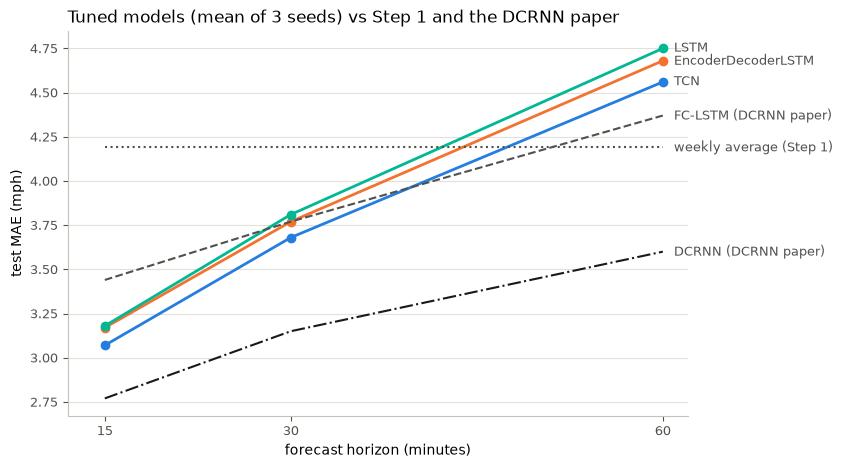

In [70]:
# test MAE at 15 / 30 / 60 min
step1 = {'last value (Step 1)': [4.02, 5.10, 6.80], 'weekly average (Step 1)': [4.19, 4.19, 4.19]}
paper = {'HA (DCRNN paper)': [4.16, 4.16, 4.16], 'FC-LSTM (DCRNN paper)': [3.44, 3.77, 4.37],
         'DCRNN (DCRNN paper)': [2.77, 3.15, 3.60]}
ours = tuned.groupby('model')[['MAE 15', 'MAE 30', 'MAE 60']].mean().loc[ORDER]
dcrnn_size = final[final.run == 'dcrnn_size_seed42'].set_index('model')[['MAE 15', 'MAE 30', 'MAE 60']]
dcrnn_size.index = ['EncoderDecoderLSTM, FC-LSTM size (seed 42)']

compare = pd.concat([pd.DataFrame(step1, index=ours.columns).T, ours, dcrnn_size,
                     pd.DataFrame(paper, index=ours.columns).T]).round(2)
compare.columns = ['15 min', '30 min', '60 min']
display(compare)

# plot: the three best models vs the references
SERIES = {'TCN': '#257de0', 'EncoderDecoderLSTM': '#f47230', 'LSTM': '#00b894'}
REFS = {'weekly average (Step 1)': (INK2, ':'), 'FC-LSTM (DCRNN paper)': (INK2, '--'),
        'DCRNN (DCRNN paper)': ('#191919', '-.')}
x = [15, 30, 60]
fig, ax = plt.subplots(figsize=(8, 5))
for name, color in SERIES.items():
    ax.plot(x, compare.loc[name], color=color, lw=2, marker='o', ms=6, label=name)
for name, (color, ls) in REFS.items():
    ax.plot(x, compare.loc[name], color=color, lw=1.5, ls=ls, label=name)
for name in list(SERIES) + list(REFS):                               
    ax.annotate(name, (60, compare.loc[name, '60 min']), xytext=(8, 0), textcoords='offset points',
                va='center', fontsize=9, color=INK2)
ax.set_xticks(x)
ax.set_xlim(12, 62)
ax.set_xlabel('forecast horizon (minutes)')
ax.set_ylabel('test MAE (mph)')
ax.set_title('Tuned models (mean of 3 seeds) vs Step 1 and the DCRNN paper', fontsize=12, loc='left')
style(ax)
plt.savefig('notebooks/plots/step2_tuned_vs_references.png', dpi=150, bbox_inches='tight')
plt.show()

- All models beat the last-value rule at every horizon. LSTM, encoder-decoder LSTM and TCN also beat the weekly average at 15 and 30 minutes, but at 60 minutes the weekly average (4.19) is still better than every model (best: TCN 4.56).
- Our weekly average (4.19) matches the paper's historical average (HA, 4.16): a sign that the data and the metric are the same.
- **FC-LSTM** (the paper's model without spatial information): our TCN is better at 15 and 30 minutes (3.07 vs 3.44, 3.68 vs 3.77) but worse at 60 minutes (4.56 vs 4.37). Our encoder-decoder LSTM, built like FC-LSTM, matches it at 30 minutes (3.77). Even at FC-LSTM's size (2 × 256 units, 1.6 M parameters, 44× more) it gains only 0.015 at 60 minutes (4.66), within the seed spread: size is not what is missing. The paper does not say whether FC-LSTM sees all sensors or the time of day, and it used peephole connections and a learning rate of 0.0001, so this comparison is approximate.
- **DCRNN**, which uses the road graph, is far better at every horizon (2.77 / 3.15 / 3.60). The gap to our best model grows with the horizon: 0.30 mph at 15 minutes, 0.53 at 30, 0.96 at 60.

### All sensors as input (task 10)

Same MLP (Eduard's defaults: 2 layers × 256 units, dropout 0.5), same inputs (speed + time of day + day of week), seeds 42, 1, 2. Only the input differs:
- **one sensor:** each sensor is its own example, one shared model (as in every Step 2 model);
- **all sensors:** one example = the last 12 values of all 207 sensors, predicting all 207 at once.

Trained on Kaggle (`kaggle/kaggle_mlp.ipynb`) with `nn_tuning final --models MLP --defaults`, plus `--params '{"input_size": 207}'` for all sensors. The table uses `final` from the task-9 cell: run that cell first.

In [71]:
mlp = final[final.model == 'MLP'].sort_values('seed')
g = mlp.groupby(mlp.run.str.replace(r'_seed\d+$', '', regex=True))     # 'one_sensor' / 'all_sensors'
task10 = pd.DataFrame({'parameters': g.parameters.first().map('{:,}'.format),
                       'best / last epoch (seeds 1, 2, 42)': g[['best epoch', 'last epoch']].apply(
                           lambda d: ', '.join(f'{b}/{l}' for b, l in zip(d['best epoch'], d['last epoch']))),
                       'minutes per epoch': (g.minutes.sum() / g['last epoch'].sum()).round(1)})
for col in ['val MAE', 'MAE 15', 'MAE 30', 'MAE 60']:                    # mean ± std over the 3 seeds
    task10[col] = g[col].mean().map('{:.3f}'.format) + ' ± ' + g[col].std().map('{:.3f}'.format)
task10.loc[['one_sensor', 'all_sensors']]

,parameters,"best / last epoch (seeds 1, 2, 42)",minutes per epoch,val MAE,MAE 15,MAE 30,MAE 60
run,,,,,,,
one_sensor,"84,492","8/13, 12/17, 24/29",0.1,3.580 ± 0.042,3.364 ± 0.060,4.035 ± 0.063,5.076 ± 0.049
all_sensors,"1,352,628","6/11, 7/12, 6/11",0.1,4.000 ± 0.032,4.260 ± 0.082,4.378 ± 0.094,4.682 ± 0.081


- **It hurts at 15 and 30 minutes** (test MAE 3.36 → 4.26 and 4.04 → 4.38) and **helps at 60 minutes** (5.08 → 4.68), for every seed. On validation (all horizons) it is worse: 4.00 vs 3.58.
- It overfits fast: 16× more parameters (1.35 M) but 207× fewer examples, one per time window; its best epoch is 6–7. It has to learn "continue this sensor's recent values" separately for each of the 207 outputs, which a shared model learns once.
- The 60-minute gain has two possible causes that this test cannot separate: information from other sensors (for example congestion upstream), or knowing which sensor is which (each output belongs to one sensor, so it can learn each sensor's usual speed at that time, like the weekly average).
- At 60 minutes it is still behind the TCN (4.56) and the weekly average (4.19). Using other sensors without structure does not replace the graph: Step 3 uses the neighbours with a shared model per sensor.

### Where the model fails (task 7)

#### Test errors per window, step and sensor

In [72]:
import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd


def load_errors(model, run):
    """Absolute test errors [windows, 12 steps, 207 sensors] in mph, NaN where the target is missing.
    BasicTS writes the results as raw binary despite the .npy name, so np.load fails: use np.fromfile."""
    run_dir = next(Path(f'checkpoints/{model}/{run}').glob('*/'))
    read = lambda name: np.fromfile(run_dir / 'test_results' / name, dtype=np.float32).reshape(-1, 12, 207)
    pred, true = read('prediction.npy'), read('targets.npy')
    return np.where(true != 0, np.abs(pred - true), np.nan)


errors = {'Linear': load_errors('Linear', 'METR-LA_100_12_12'),
          'LSTM': load_errors('LSTM', 'METR-LA_10_12_12'),
          'TCN': load_errors('TCN', 'METR-LA_10_12_12')}


#### Error per sensor on the road graph

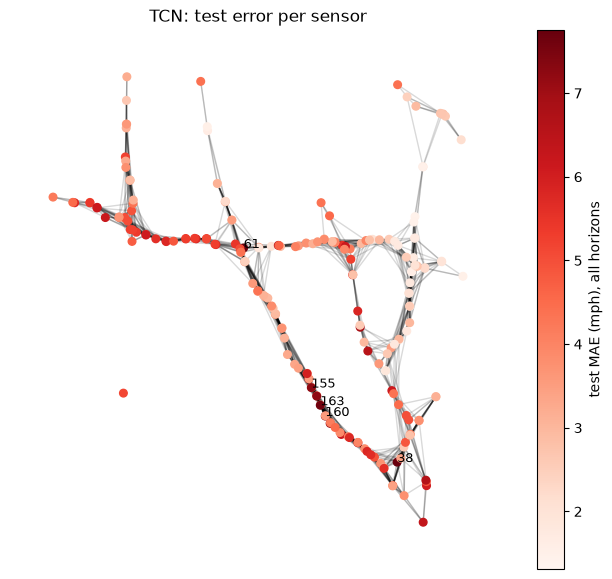

In [73]:
per_sensor = np.nanmean(errors['TCN'], axis=(0, 1))            # one MAE per sensor

loc = pd.read_csv('data/METR-LA/graph_sensor_locations.csv')
with open('data/METR-LA/adj_mx.pkl', 'rb') as f:
    sensor_ids, _, adj = pickle.load(f, encoding='latin1')
A = adj.copy()
np.fill_diagonal(A, 0)
G = nx.from_numpy_array(A > 0, create_using=nx.DiGraph)
pos = {i: (loc.longitude[i], loc.latitude[i]) for i in range(207)}

plt.figure(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, alpha=0.15, arrows=False)
nodes = nx.draw_networkx_nodes(G, pos, nodelist=list(range(207)), node_color=per_sensor, cmap='Reds', node_size=30)
plt.colorbar(nodes, label='test MAE (mph), all horizons')
for i in np.argsort(per_sensor)[-5:]:                          # label the 5 worst sensors
    plt.annotate(str(i), pos[i], fontsize=9)
plt.title('TCN: test error per sensor')
plt.axis('off')
plt.savefig('notebooks/plots/step2_error_map.png', dpi=150, bbox_inches='tight')
plt.show()


Per-sensor test MAE ranges from 1.3 to 7.8 mph (median 3.7). The five worst sensors (61, 38, 163, 155, 160; 7.2–7.8 mph) are partly clustered: 155, 160 and 163 are neighbours on the graph, within 1.7 km of each other on one stretch of road, while 61 and 38 are elsewhere (6–15 km away). All five have speeds that vary about twice as much as a typical sensor (standard deviation 20–25 mph vs a median of 10.8), that is frequent switches between free flow and congestion, which a model that sees only one sensor's past cannot anticipate. A cluster of hard neighbours suggests congestion that travels along that road, which the graph models of Step 3 can use.

### Error by time of day (task 8)
#### Error by hour, all horizons

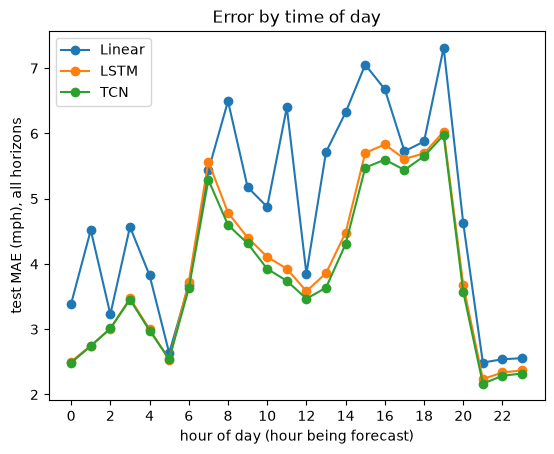

In [74]:
import numpy as np

ts = np.load('data/METR-LA/test_timestamps.npy')
W = errors['TCN'].shape[0]
idx = np.arange(W)[:, None] + 12 + np.arange(12)[None, :]     # time step of every target in the test split
hour = (ts[idx, 0] * 24).astype(int)                          # its hour of day, shape [windows, 12]

for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[hour == h]) for h in range(24)], marker='o', label=name)
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of day (hour being forecast)')
plt.ylabel('test MAE (mph), all horizons')
plt.title('Error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour.png', dpi=150, bbox_inches='tight')
plt.show()

Errors are grouped by the hour of the value being predicted, not the hour when the forecast was made: a 60-minute forecast made at 16:00 counts under 17:00.

Errors are lowest at night and highest in the rush hours, about twice as large around 17:00–19:00 as at night. Errors are larger when traffic changes quickly.

#### 60-minute forecasts vs the weekly average

weekly average MAE (60-min targets): 4.19


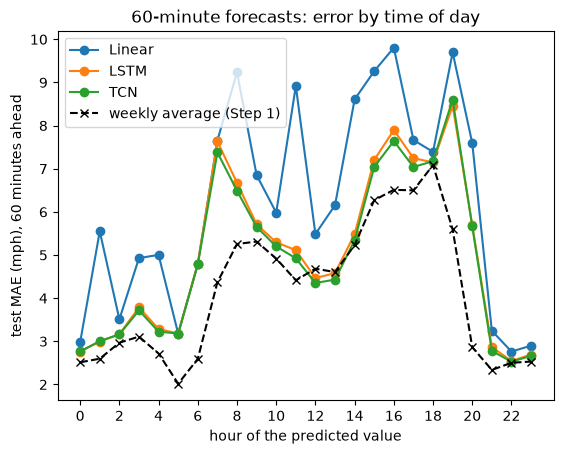

In [75]:
def week_slot(t):
    """Timestamps [..., 2] -> slot 0..2015 of the week (day of week * 288 + 5-min step of the day)."""
    return (np.round(t[..., 1] * 7).astype(int) % 7) * 288 + np.round(t[..., 0] * 288).astype(int) % 288

# weekly-average rule from Step 1: mean speed per (day of week, time of day) slot, from the training data
train = np.load('data/METR-LA/train_data.npy')
train_slot = week_slot(np.load('data/METR-LA/train_timestamps.npy'))
train = np.where(train == 0, np.nan, train)                            # skip missing values in the average
week = np.stack([np.nanmean(train[train_slot == s], axis=0) for s in range(2016)])   # [2016 slots, 207]

# its errors on the same 60-minute targets as the models
test = np.load('data/METR-LA/test_data.npy')
t60 = idx[:, 11]                                                       # time step of each 60-min target
true60 = test[t60]                                                     # [windows, 207]
err_week = np.where(true60 != 0, np.abs(week[week_slot(ts[t60])] - true60), np.nan)
print('weekly average MAE (60-min targets): %.2f' % np.nanmean(err_week))   # should be 4.19, as in Step 1

hour60 = hour[:, 11]                                                   # hour of each 60-min target
for name, err in errors.items():
    plt.plot(range(24), [np.nanmean(err[:, 11][hour60 == h]) for h in range(24)], marker='o', label=name)
plt.plot(range(24), [np.nanmean(err_week[hour60 == h]) for h in range(24)], 'k--', marker='x', label='weekly average (Step 1)')
plt.xticks(range(0, 24, 2))
plt.xlabel('hour of the predicted value')
plt.ylabel('test MAE (mph), 60 minutes ahead')
plt.title('60-minute forecasts: error by time of day')
plt.legend()
plt.savefig('notebooks/plots/step2_error_by_hour_60min.png', dpi=150, bbox_inches='tight')
plt.show()


One hour ahead, the weekly average beats all models for most of the day, especially at the start of the morning rush (06–08) and the end of the evening rush (19–20): from the last hour alone, a model cannot know that a rush is about to start or end. Around midday the models are as good as the weekly average.